JANASREE 24BAD040
11490434/11490434 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Number of images: 60000
Image dimensions: (28, 28)


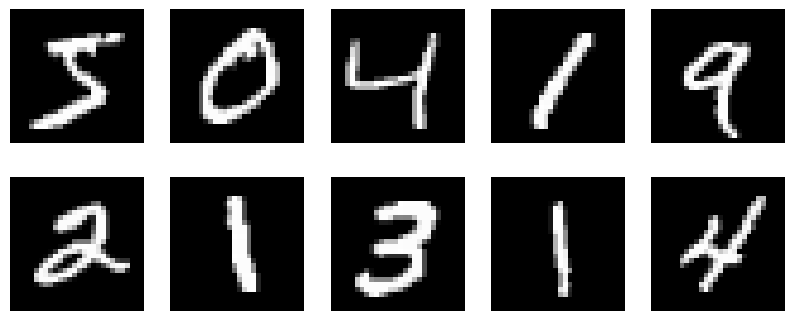

New shape: (60000, 28, 28, 1)
Dataset prepared successfully


In [2]:
import tensorflow as tf
from tensorflow.keras import layers
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
print("JANASREE 24BAD040")
# Load MNIST dataset
(x_train, _), (_, _) = tf.keras.datasets.mnist.load_data()

print("Number of images:", x_train.shape[0])
print("Image dimensions:", x_train.shape[1:])

# Display sample images
plt.figure(figsize=(10, 4))

for i in range(10):
    plt.subplot(2, 5, i + 1)
    plt.imshow(x_train[i], cmap="gray")
    plt.axis("off")

plt.show()

# Normalize pixels to [-1, 1]
x_train = x_train.astype("float32")
x_train = (x_train - 127.5) / 127.5

# Reshape images
x_train = np.expand_dims(x_train, axis=-1)

print("New shape:", x_train.shape)

# Create TensorFlow dataset
BATCH_SIZE = 128

dataset = tf.data.Dataset.from_tensor_slices(x_train)
dataset = dataset.shuffle(60000).batch(BATCH_SIZE)

print("Dataset prepared successfully")

JANASREE 24BAD040


/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/dense.py:106: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 12544)          │     1,254,400 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 12544)          │        50,176 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ leaky_re_lu (LeakyReLU)         │ (None, 12544)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ reshape (Reshape)               │ (None, 7, 7, 256)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_transpose                │ (None, 7, 7, 128)      │       819,200 │
│ (Conv2DTranspose)               │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 7, 7, 128)      │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ leaky_re_lu_1 (LeakyReLU)       │ (None, 7, 7, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_transpose_1              │ (None, 14, 14, 64)     │       204,800 │
│ (Conv2DTranspose)               │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 14, 14, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ leaky_re_lu_2 (LeakyReLU)       │ (None, 14, 14, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_transpose_2              │ (None, 28, 28, 1)      │         1,600 │
│ (Conv2DTranspose)               │                        │               │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,330,944 (8.89 MB)

 Trainable params: 2,305,472 (8.79 MB)

 Non-trainable params: 25,472 (99.50 KB)

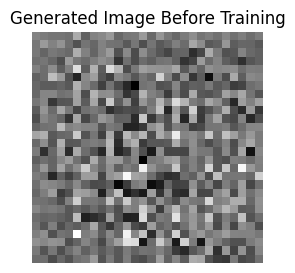

In [3]:
# Generator
noise_dim = 100
print("JANASREE 24BAD040")
generator = tf.keras.Sequential([
    layers.Dense(7 * 7 * 256, use_bias=False, input_shape=(noise_dim,)),
    layers.BatchNormalization(),
    layers.LeakyReLU(),
    layers.Reshape((7, 7, 256)),
    layers.Conv2DTranspose(
        128, (5, 5),
        strides=(1, 1),
        padding="same",
        use_bias=False
    ),
    layers.BatchNormalization(),
    layers.LeakyReLU(),
    layers.Conv2DTranspose(
        64, (5, 5),
        strides=(2, 2),
        padding="same",
        use_bias=False
    ),
    layers.BatchNormalization(),
    layers.LeakyReLU(),
    layers.Conv2DTranspose(
        1, (5, 5),
        strides=(2, 2),
        padding="same",
        use_bias=False,
        activation="tanh"
    )
])
generator.summary()
noise = tf.random.normal([1, noise_dim])
generated_image = generator(noise, training=False)
plt.figure(figsize=(3, 3))
plt.imshow(generated_image[0, :, :, 0], cmap="gray")
plt.axis("off")
plt.title("Generated Image Before Training")
plt.show()

In [4]:
print("JANASREE 24BAD040")
# Discriminator
discriminator = tf.keras.Sequential([
    layers.Conv2D(
        64, (5, 5),
        strides=(2, 2),
        padding="same",
        input_shape=[28, 28, 1]
    ),
    layers.LeakyReLU(),
    layers.Dropout(0.3),

    layers.Conv2D(
        128, (5, 5),
        strides=(2, 2),
        padding="same"
    ),
    layers.LeakyReLU(),
    layers.Dropout(0.3),

    layers.Flatten(),
    layers.Dense(1)
])

discriminator.summary()

# Loss function
cross_entropy = tf.keras.losses.BinaryCrossentropy(
    from_logits=True
)
# Discriminator loss
def discriminator_loss(real_output, fake_output):
    real_loss = cross_entropy(
        tf.ones_like(real_output),
        real_output
    )

    fake_loss = cross_entropy(
        tf.zeros_like(fake_output),
        fake_output
    )

    return real_loss + fake_loss

# Generator loss
def generator_loss(fake_output):
    return cross_entropy(
        tf.ones_like(fake_output),
        fake_output
    )
# Optimizers
generator_optimizer = tf.keras.optimizers.Adam(
    learning_rate=0.0002,
    beta_1=0.5
)
discriminator_optimizer = tf.keras.optimizers.Adam(
    learning_rate=0.0002,
    beta_1=0.5
)
print("Generator and Discriminator are ready")

JANASREE 24BAD040


/usr/local/lib/python3.13/dist-packages/keras/src/layers/convolutional/base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 14, 14, 64)     │         1,664 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ leaky_re_lu_3 (LeakyReLU)       │ (None, 14, 14, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 14, 14, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 7, 7, 128)      │       204,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ leaky_re_lu_4 (LeakyReLU)       │ (None, 7, 7, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 7, 7, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 6272)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │         6,273 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 212,865 (831.50 KB)

 Trainable params: 212,865 (831.50 KB)

 Non-trainable params: 0 (0.00 B)

Generator and Discriminator are ready


JANASREE 24BAD040
Epoch: 1 Generator Loss: 0.7022 Discriminator Loss: 1.3232
Epoch: 2 Generator Loss: 0.7396 Discriminator Loss: 1.3484
Epoch: 3 Generator Loss: 0.7893 Discriminator Loss: 1.2986
Epoch: 4 Generator Loss: 0.8484 Discriminator Loss: 1.2544


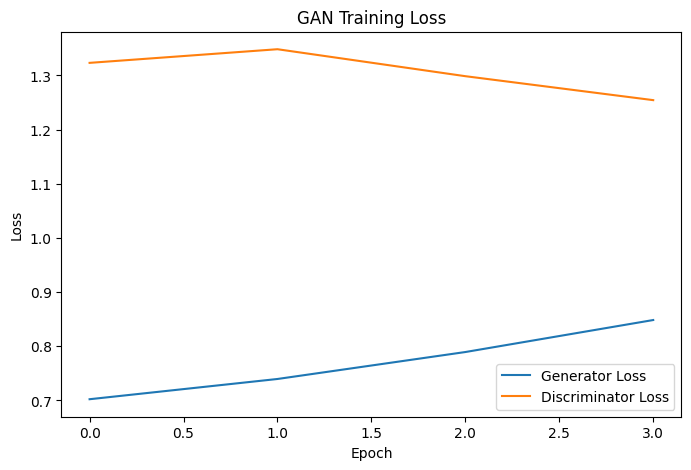

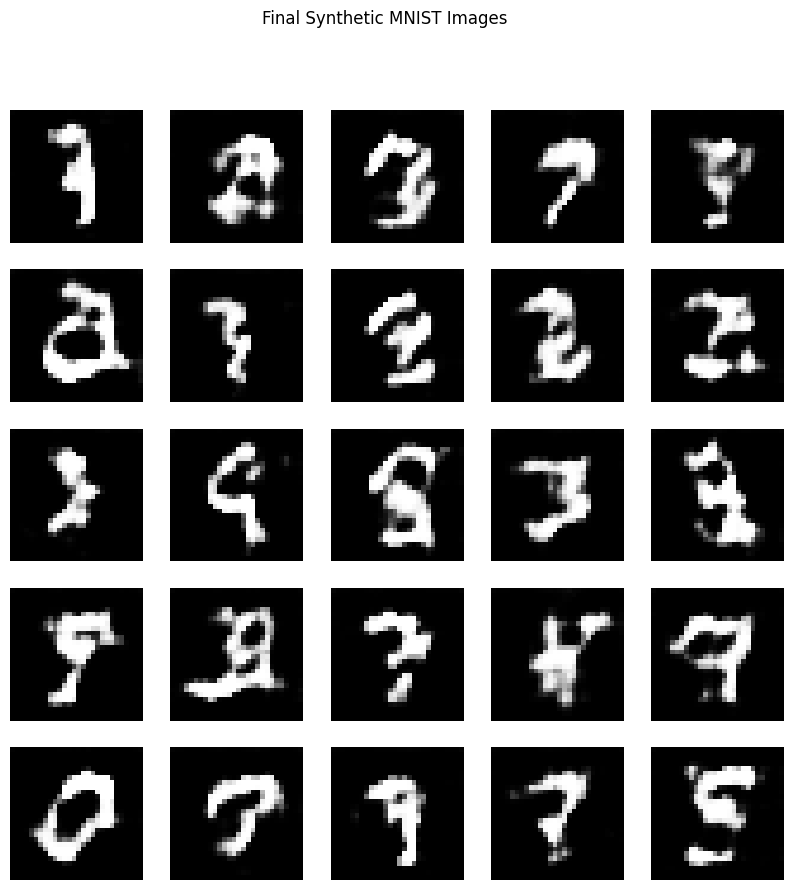

25 synthetic images saved successfully.
Experiment 7 completed successfully!


In [5]:
print("JANASREE 24BAD040")

# Training parameters
EPOCHS = 4
num_examples_to_generate = 16

# Fixed noise for visualization
seed = tf.random.normal(
    [num_examples_to_generate, noise_dim]
)

generator_losses = []
discriminator_losses = []


@tf.function
def train_step(images):

    noise = tf.random.normal(
        [BATCH_SIZE, noise_dim]
    )

    with tf.GradientTape() as gen_tape, tf.GradientTape() as disc_tape:

        generated_images = generator(
            noise,
            training=True
        )

        real_output = discriminator(
            images,
            training=True
        )

        fake_output = discriminator(
            generated_images,
            training=True
        )

        gen_loss = generator_loss(fake_output)

        disc_loss = discriminator_loss(
            real_output,
            fake_output
        )

    gradients_of_generator = gen_tape.gradient(
        gen_loss,
        generator.trainable_variables
    )

    gradients_of_discriminator = disc_tape.gradient(
        disc_loss,
        discriminator.trainable_variables
    )

    generator_optimizer.apply_gradients(
        zip(
            gradients_of_generator,
            generator.trainable_variables
        )
    )

    discriminator_optimizer.apply_gradients(
        zip(
            gradients_of_discriminator,
            discriminator.trainable_variables
        )
    )

    return gen_loss, disc_loss


def generate_and_show_images(epoch):

    predictions = generator(
        seed,
        training=False
    )

    fig = plt.figure(figsize=(8, 8))

    for i in range(predictions.shape[0]):

        plt.subplot(4, 4, i + 1)

        plt.imshow(
            predictions[i, :, :, 0] * 127.5 + 127.5,
            cmap="gray"
        )

        plt.axis("off")

    plt.suptitle(
        "Generated Images - Epoch " + str(epoch)
    )

    plt.show()


# GAN Training
for epoch in range(EPOCHS):

    total_gen_loss = 0
    total_disc_loss = 0
    batches = 0

    for image_batch in dataset:

        gen_loss, disc_loss = train_step(image_batch)

        total_gen_loss += gen_loss
        total_disc_loss += disc_loss
        batches += 1

    avg_gen_loss = total_gen_loss / batches
    avg_disc_loss = total_disc_loss / batches

    generator_losses.append(float(avg_gen_loss))
    discriminator_losses.append(float(avg_disc_loss))

    print(
        "Epoch:",
        epoch + 1,
        "Generator Loss:",
        round(float(avg_gen_loss), 4),
        "Discriminator Loss:",
        round(float(avg_disc_loss), 4)
    )

    if (epoch + 1) % 5 == 0:
        generate_and_show_images(epoch + 1)


# Plot GAN Training Loss
plt.figure(figsize=(8, 5))

plt.plot(
    generator_losses,
    label="Generator Loss"
)

plt.plot(
    discriminator_losses,
    label="Discriminator Loss"
)

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("GAN Training Loss")

plt.legend()
plt.show()


# Generate Final Synthetic Images
final_noise = tf.random.normal(
    [25, noise_dim]
)

final_images = generator(
    final_noise,
    training=False
)

plt.figure(figsize=(10, 10))
for i in range(25):
    plt.subplot(5, 5, i + 1)
    plt.imshow(
        final_images[i, :, :, 0] * 127.5 + 127.5,
        cmap="gray"
    )

    plt.axis("off")

plt.suptitle("Final Synthetic MNIST Images")
plt.show()

# SAVE GENERATED IMAGES


import os

os.makedirs(
    "generated_images",
    exist_ok=True
)

for i in range(25):

    image = (
        final_images[i] * 127.5 + 127.5
    )

    image = tf.cast(
        image,
        tf.uint8
    )

    tf.keras.utils.save_img(
        f"generated_images/image_{i + 1}.png",
        image
    )

print("25 synthetic images saved successfully.")
print("Experiment 7 completed successfully!")